# Raghavan et al. 2021 — PDAC (Seq-Well)
## 04 · EMT-TF expression (unconditional final step)

Score a wide mesenchymal-TF panel (Snail/Zeb/Twist **plus** FOXC/PRRX) gated on detectable expression; overlay the two most pseudotime-informative TFs as thresholded expressers on the grey manifold.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude',cat,name)
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude',cat,name)
adata = sc.read_h5ad(os.path.join(pth_out,'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 7830 | pseudotime 0.0 -> 12.38


### Panel scoring — detection-gated, wide mesenchymal families

In [3]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn,1/3); late = tn >= np.quantile(tn,2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair (frac_expr>0.03): {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC1      0.236       0.178      0.101    -0.160    EARLY(root)
 PRRX2      0.040       0.026      0.009    -0.101    EARLY(root)
  ZEB1      0.083       0.057      0.053    -0.069    EARLY(root)
 SNAI2      0.077       0.034      0.029    -0.044    EARLY(root)
 SNAI1      0.013       0.006      0.006    -0.024 LATE(terminus)
 PRRX1      0.005       0.002      0.003    -0.012 LATE(terminus)
TWIST1      0.004       0.001      0.003    -0.008 LATE(terminus)
  ZEB2      0.064       0.028      0.090     0.067 LATE(terminus)

derived pair (frac_expr>0.03): FOXC1 (early/root) <-> ZEB2 (late/terminus)


### Overlay — thresholded expressers on the grey manifold (house style)

overlay thresholds (upper quartile among expressers): {'FOXC1': 0.817, 'ZEB2': 0.973} | cells shown: {'FOXC1': 463, 'ZEB2': 126}
FOXC1: 23.6% expressing; 463 shown; mean pseudotime of shown = 0.45 (all = 0.49)
ZEB2: 6.4% expressing; 126 shown; mean pseudotime of shown = 0.82 (all = 0.49)
saved expression.pdf


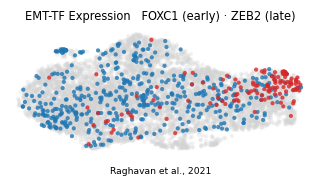

In [4]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos,0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in sel},
      '| cells shown:', {g: int(sel[g].sum()) for g in sel})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) \u00b7 {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown; mean pseudotime of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')